<a href="https://colab.research.google.com/github/Dihen20242099G-Hub/CRM-CM-CW01/blob/main/CRM_%26_CM_CW1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Task 1.1
# Import required libraries
import pandas as pd
import numpy as np
import requests
from io import StringIO
from datetime import datetime

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:
# Wikipedia source
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

# Request the webpage
headers = {"User-Agent": "Mozilla/5.0"}

response = requests.get(url, headers=headers)

# Check the response
print("Status code:", response.status_code)

# Extract the S&P 500 table
if response.status_code == 200:

    tables = pd.read_html(StringIO(response.text))

    # Select the company table
    sp500 = tables[0]

    # Display first five companies
    display(sp500.head())

    # Display total number of companies
    print("Total companies:", len(sp500))

else:
    print("Unable to access Wikipedia. Please try again.")


Status code: 200


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989


Total companies: 503


In [ ]:
# Record the retrieval date
retrieval_date = datetime.now().strftime("%Y-%m-%d")

print("Retrieval date:", retrieval_date)

# Save the S&P 500 ticker list
sp500.to_csv("sp500_tickers.csv", index=False)

print("S&P 500 ticker list saved successfully!")

Retrieval date: 2026-11-22
S&P 500 ticker list saved successfully!


In [ ]:
# Install yfinance
!pip install yfinance

# Import yfinance
import yfinance as yf

print("yfinance imported successfully!")

yfinance imported successfully!


In [ ]:
# Convert Wikipedia ticker symbols into Yahoo Finance format
tickers = sp500["Symbol"].str.replace(".", "-", regex=False).tolist()

# Add S&P 500 benchmark
tickers.append("^GSPC")

# Download daily historical data
start_date = "2021-01-01"
end_date = "2025-01-01"

stock_data = yf.download(
    tickers,
    start=start_date,
    end=end_date,
    auto_adjust=False,
    group_by="ticker",
    progress=True
)

print("Data downloaded successfully!")

[*********************100%***********************]  504 of 504 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['SNDK', 'VYLR', 'Q', 'FDXF', 'HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Data downloaded successfully!


In [ ]:
# Identify tickers with available historical data
valid_tickers = []

for ticker in tickers:
    if ticker in stock_data.columns.get_level_values(0):
        if not stock_data[ticker].dropna(how="all").empty:
            valid_tickers.append(ticker)

# Identify failed tickers
failed_tickers = [ticker for ticker in tickers if ticker not in valid_tickers]

print("Successfully downloaded:", len(valid_tickers))
print("Failed tickers:", failed_tickers)
print("Number of failed tickers:", len(failed_tickers))

Successfully downloaded: 499
Failed tickers: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']
Number of failed tickers: 5


In [ ]:
# Display the downloaded data structure
print("Dataset shape:", stock_data.shape)

# Display available columns
print("\nAvailable data fields:")
print(stock_data.columns.get_level_values(1).unique().tolist())

# Display the first five rows
display(stock_data.head())

Dataset shape: (1005, 3024)

Available data fields:
['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']


Ticker              EG                                                  \
Price             Open        High         Low       Close   Adj Close   
Date                                                                     
2021-01-04  235.000000  235.910004  226.770004  228.110001  203.595001   
2021-01-05  228.080002  229.679993  225.580002  226.229996  201.916992   
2021-01-06  229.630005  240.509995  229.460007  239.639999  213.885818   
2021-01-07  241.240005  241.809998  238.250000  241.360001  215.420990   
2021-01-08  241.300003  241.860001  236.009995  238.970001  213.287811   

Ticker                    SYY                                   ...  \
Price       Volume       Open       High        Low      Close  ...   
Date                                                            ...   
2021-01-04  165100  74.139999  74.379997  70.750000  72.309998  ...   
2021-01-05  158600  72.019997  73.769997  72.019997  72.769997  ...   
2021-01-06  309900  73.239998  76.059998  73.010002  76.000000  ...   
2021-01-07  259400  75.940002  76.389999  74.489998  75.589996  ...   
2021-01-08  209700  75.529999  77.820000  75.209999  77.550003  ...   

Ticker             DTE                                        AEP             \
Price              Low       Close  Adj Close   Volume       Open       High   
Date                                                                           
2021-01-04  101.199997  101.608513  84.072548   986765  83.330002  83.440002   
2021-01-05  100.714897  101.770210  84.206337   958918  81.800003  82.050003   
2021-01-06  102.382980  103.591492  85.713303   752588  81.120003  82.739998   
2021-01-07  100.970215  101.072342  83.628929  1268530  82.449997  82.449997   
2021-01-08   99.634041  100.587234  83.227547  1011558  79.669998  80.019997   

Ticker                                                
Price             Low      Close  Adj Close   Volume  
Date                                                  
2021-01-04  81.209999  81.540001  65.872757  3232900  
2021-01-05  80.970001  81.430000  65.783875  2212300  
2021-01-06  80.620003  82.080002  66.308990  2713900  
2021-01-07  79.870003  79.889999  64.539780  2764400  
2021-01-08  78.610001  79.180000  63.966202  3059800  

[5 rows x 3024 columns]

In [ ]:
# Check S&P 500 benchmark availability
if "^GSPC" in stock_data.columns.get_level_values(0):
    print("S&P 500 benchmark downloaded successfully!")
else:
    print("S&P 500 benchmark is missing!")

S&P 500 benchmark downloaded successfully!


In [ ]:
# Save the downloaded stock data
stock_data.to_pickle("sp500_stock_data.pkl")

print("Stock data saved successfully!")

Stock data saved successfully!


In [ ]:
from google.colab import files

files.download("sp500_stock_data.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Task 1.2
# Check for duplicate dates
duplicate_dates = stock_data.index.duplicated().sum()

print("Number of duplicate dates:", duplicate_dates)

# Check the date range
print("First date:", stock_data.index.min())
print("Last date:", stock_data.index.max())

Number of duplicate dates: 0
First date: 2021-01-04 00:00:00
Last date: 2024-12-31 00:00:00


In [ ]:
# Count total missing values
total_missing = stock_data.isnull().sum().sum()

print("Total missing values:", total_missing)

# Calculate missing values for each ticker
missing_by_ticker = (
    stock_data.isnull()
    .T.groupby(level=0)
    .sum()
    .sum(axis=1)
)

# Display tickers with missing values
print("\nTickers with missing values:")
print(
    missing_by_ticker[missing_by_ticker > 0]
    .sort_values(ascending=False)
)

Total missing values: 55266

Tickers with missing values:
Ticker
FDXF    6030
Q       6030
HONA    6030
SNDK    6030
VYLR    6030
GEV     4872
SOLV    4866
RDDT    4848
VLTO    4152
GEHC    2952
CEG     1578
HOOD     858
APP      420
COIN     414
EXE      156
dtype: int64


In [ ]:
# Create a summary of available data for each ticker
history_summary = []

for ticker in stock_data.columns.get_level_values(0).unique():

    ticker_data = stock_data[ticker]

    # Use Close prices to identify available trading dates
    valid_data = ticker_data["Close"].dropna()

    history_summary.append({
        "Ticker": ticker,
        "Available Days": len(valid_data),
        "Missing Days": len(stock_data) - len(valid_data),
        "First Available Date": valid_data.index.min(),
        "Last Available Date": valid_data.index.max()
    })

# Convert results into a DataFrame
history_summary = pd.DataFrame(history_summary)

# Display companies with incomplete histories
display(
    history_summary[
        history_summary["Missing Days"] > 0
    ].sort_values("Missing Days", ascending=False)
)

,Ticker,Available Days,Missing Days,First Available Date,Last Available Date
19,SNDK,0,1005,NaT,NaT
65,VYLR,0,1005,NaT,NaT
218,FDXF,0,1005,NaT,NaT
124,Q,0,1005,NaT,NaT
221,HONA,0,1005,NaT,NaT
308,GEV,193,812,2024-03-27,2024-12-31
482,SOLV,194,811,2024-03-26,2024-12-31
244,RDDT,197,808,2024-03-21,2024-12-31
80,VLTO,313,692,2023-10-04,2024-12-31
498,GEHC,513,492,2022-12-15,2024-12-31


In [ ]:
# Check non-positive prices and invalid volumes

price_columns = ["Open", "High", "Low", "Close", "Adj Close"]

for column in price_columns:
    invalid_prices = (stock_data.xs(
        column, axis=1, level=1
    ) <= 0).sum().sum()

    print(f"Invalid {column} values:", invalid_prices)

# Check zero and negative trading volumes
volume_data = stock_data.xs("Volume", axis=1, level=1)

print("\nZero volume values:", (volume_data == 0).sum().sum())
print("Negative volume values:", (volume_data < 0).sum().sum())

Invalid Open values: 0
Invalid High values: 0
Invalid Low values: 0
Invalid Close values: 0
Invalid Adj Close values: 0

Zero volume values: 452
Negative volume values: 0


In [ ]:
# Identify zero-volume records
zero_volume = volume_data == 0

# Count zero-volume records for each ticker
zero_volume_by_ticker = zero_volume.sum()

print("Tickers with zero-volume records:")
print(
    zero_volume_by_ticker[zero_volume_by_ticker > 0]
    .sort_values(ascending=False)
)

# Display the first 10 zero-volume records
zero_volume_records = zero_volume.stack()
zero_volume_records = zero_volume_records[zero_volume_records]

print("\nFirst 10 zero-volume records:")
display(zero_volume_records.head(10))

Tickers with zero-volume records:
Ticker
SW       424
FERG      27
^GSPC      1
dtype: int64

First 10 zero-volume records:


Date        Ticker
2021-01-05  SW        True
2021-01-06  SW        True
2021-01-07  FERG      True
2021-01-08  FERG      True
2021-01-12  FERG      True
            SW        True
2021-01-13  FERG      True
            SW        True
2021-01-14  FERG      True
2021-01-15  FERG      True
dtype: bool

In [ ]:
# Inspect zero-volume records for SW and FERG

for ticker in ["SW", "FERG", "^GSPC"]:

    print("\nTicker:", ticker)

    zero_dates = stock_data.loc[
        stock_data[(ticker, "Volume")] == 0
    ]

    display(
        zero_dates.loc[:, ticker]
        .head(10)
    )


Ticker: SW


Price,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2021-01-05,47.610001,47.610001,47.610001,47.610001,38.435078,0
2021-01-06,47.610001,47.610001,47.610001,47.610001,38.435078,0
2021-01-12,47.900002,47.900002,47.900002,47.900002,38.669193,0
2021-01-13,47.900002,47.900002,47.900002,47.900002,38.669193,0
2021-01-19,47.689999,47.689999,47.689999,47.689999,38.499660,0
2021-01-20,47.689999,47.689999,47.689999,47.689999,38.499660,0
2021-01-21,47.689999,47.689999,47.689999,47.689999,38.499660,0
2021-01-22,47.689999,47.689999,47.689999,47.689999,38.499660,0
2021-01-25,47.689999,47.689999,47.689999,47.689999,38.499660,0



Ticker: FERG


Price,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2021-01-07,121.300003,121.300003,121.300003,121.300003,106.624664,0
2021-01-08,121.300003,121.300003,121.300003,121.300003,106.624664,0
2021-01-12,124.199997,124.199997,124.199997,124.199997,109.173813,0
2021-01-13,124.199997,124.199997,124.199997,124.199997,109.173813,0
2021-01-14,124.199997,124.199997,124.199997,124.199997,109.173813,0
2021-01-15,124.199997,124.199997,124.199997,124.199997,109.173813,0
2021-01-20,123.000000,123.000000,123.000000,123.000000,108.118973,0
2021-01-21,123.000000,123.000000,123.000000,123.000000,108.118973,0
2021-01-22,123.000000,123.000000,123.000000,123.000000,108.118973,0



Ticker: ^GSPC


Price,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2023-05-24,4132.959961,4132.959961,4103.97998,4115.240234,4115.240234,0


In [ ]:
# Check zero-volume records and repeated closing prices

for ticker in ["SW", "FERG"]:

    data = stock_data[ticker]

    zero_volume = data["Volume"] == 0

    unchanged_price = (
        data["Close"].diff() == 0
    )

    print("\nTicker:", ticker)
    print("Zero-volume records:", zero_volume.sum())
    print("Unchanged closing prices:", unchanged_price.sum())

    print("\nZero-volume records with unchanged prices:")
    print(
        data.loc[
            zero_volume & unchanged_price,
            ["Close", "Volume"]
        ].head(10)
    )


Ticker: SW
Zero-volume records: 424
Unchanged closing prices: 486

Zero-volume records with unchanged prices:
Price           Close  Volume
Date                         
2021-01-05  47.610001       0
2021-01-06  47.610001       0
2021-01-12  47.900002       0
2021-01-13  47.900002       0
2021-01-19  47.689999       0
2021-01-20  47.689999       0
2021-01-21  47.689999       0
2021-01-22  47.689999       0
2021-01-25  47.689999       0
2021-01-26  47.689999       0

Ticker: FERG
Zero-volume records: 27
Unchanged closing prices: 30

Zero-volume records with unchanged prices:
Price            Close  Volume
Date                          
2021-01-07  121.300003       0
2021-01-08  121.300003       0
2021-01-12  124.199997       0
2021-01-13  124.199997       0
2021-01-14  124.199997       0
2021-01-15  124.199997       0
2021-01-20  123.000000       0
2021-01-21  123.000000       0
2021-01-22  123.000000       0
2021-01-25  123.000000       0


In [ ]:
# Compare Close and Adjusted Close prices

close_prices = stock_data.xs("Close", axis=1, level=1)
adjusted_prices = stock_data.xs("Adj Close", axis=1, level=1)

# Calculate the average percentage difference
price_difference = (
    (adjusted_prices - close_prices) / close_prices
) * 100

difference_summary = price_difference.mean().sort_values()

print("Average percentage difference between Close and Adjusted Close:")
display(difference_summary.head(15))

print("\nNumber of tickers with a price difference:")
print((price_difference.abs() > 0.01).any().sum())

Average percentage difference between Close and Adjusted Close:


,0
Ticker,
MO,-24.776474
VZ,-22.068205
LYB,-21.998743
F,-21.606637
DOC,-20.768270
PFE,-20.422677
VICI,-19.522637
T,-19.000036
DOW,-18.954891



Number of tickers with a price difference:
405


In [ ]:
# Download historical data including dividends and stock splits
actions_data = yf.download(
    valid_tickers,
    start="2021-01-01",
    end="2025-01-01",
    actions=True,
    auto_adjust=False,
    group_by="ticker",
    progress=True
)

# Identify dividend and stock split records
action_results = []

for ticker in valid_tickers:

    ticker_data = actions_data[ticker]

    dividends = ticker_data["Dividends"]
    splits = ticker_data["Stock Splits"]

    action_results.append({
        "Ticker": ticker,
        "Dividend Events": (dividends > 0).sum(),
        "Total Dividends": dividends.sum(),
        "Stock Split Events": (splits > 0).sum()
    })

# Create summary table
actions_summary = pd.DataFrame(action_results)

# Display tickers with corporate actions
display(
    actions_summary[
        (actions_summary["Dividend Events"] > 0) |
        (actions_summary["Stock Split Events"] > 0)
    ].head(20)
)

print(
    "\nTotal tickers with dividend events:",
    (actions_summary["Dividend Events"] > 0).sum()
)

print(
    "Total tickers with stock split events:",
    (actions_summary["Stock Split Events"] > 0).sum()
)

[*********************100%***********************]  499 of 499 completed


,Ticker,Dividend Events,Total Dividends,Stock Split Events
0,MMM,16,18.312374,1
1,AOS,16,4.720000,0
2,ABT,16,7.920000,0
3,ABBV,16,22.960000,0
4,ACN,16,17.640000,0
7,AES,16,2.592000,0
8,AFL,16,6.600000,0
9,A,17,3.708000,0
10,APD,15,24.790000,0
13,ALB,16,6.350000,0



Total tickers with dividend events: 399
Total tickers with stock split events: 53


In [ ]:
# Extract Adjusted Close prices
adj_close = stock_data.xs("Adj Close", axis=1, level=1)

# Resample into Friday-ending weeks
weekly_prices = adj_close.resample("W-FRI").last()

# Remove incomplete first and final calendar weeks
weekly_prices = weekly_prices.loc["2021-01-08":"2024-12-27"]

# Calculate weekly returns without filling missing prices
weekly_returns = weekly_prices.pct_change(fill_method=None)

# Separate benchmark and individual shares
benchmark_returns = weekly_returns["^GSPC"]
share_returns = weekly_returns.drop(columns="^GSPC")

# Align shares and benchmark using common week labels
aligned_returns = share_returns.join(
    benchmark_returns.rename("Benchmark"),
    how="inner"
)

# Display results
print("Weekly observations:", len(aligned_returns))
print("Number of columns:", len(aligned_returns.columns))
print("Missing weekly returns:", aligned_returns.isnull().sum().sum())

display(aligned_returns.head())

Weekly observations: 208
Number of columns: 504
Missing weekly returns: 2402


,EG,SYY,ADI,VTRS,CBRE,PEP,BNY,EXE,NCLH,ADBE,...,FOX,IR,CME,GEHC,MET,TER,SCHW,DTE,AEP,Benchmark
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-15,-0.032514,-0.025532,0.006444,-0.068306,0.014049,-0.019351,0.017188,NaN,0.038887,-0.055700,...,0.025996,-0.010560,-0.039363,NaN,0.035013,0.038971,-0.003900,0.045097,0.016292,-0.014754
2021-01-22,-0.009862,-0.005028,-0.013756,0.022287,0.039358,-0.019804,-0.079877,NaN,-0.031127,0.031348,...,-0.040145,-0.014812,-0.040559,NaN,-0.005475,0.004734,-0.005958,-0.013034,0.020008,0.019431
2021-01-29,-0.077931,-0.048942,-0.053027,-0.025244,-0.076340,-0.014575,-0.042791,NaN,-0.078894,-0.028935,...,0.024683,-0.074950,-0.012497,NaN,-0.053284,-0.177383,-0.117466,-0.026167,-0.014254,-0.033120
2021-02-05,0.039416,0.077891,0.009706,0.053561,0.105608,0.032145,0.055235,NaN,0.091391,0.072694,...,0.014051,0.046367,0.053098,NaN,0.102275,0.111385,0.081490,0.025269,0.015820,0.046467


In [ ]:
# Count valid weekly returns for each stock
valid_weekly_counts = aligned_returns.drop(columns="Benchmark").count()

# Identify stocks with complete weekly return histories
complete_tickers = valid_weekly_counts[
    valid_weekly_counts == valid_weekly_counts.max()
].index.tolist()

print("Maximum valid weekly returns:", valid_weekly_counts.max())
print("Number of stocks with complete histories:", len(complete_tickers))

print("\nStocks with the lowest number of valid weekly returns:")
display(valid_weekly_counts.sort_values().head(15))

print("\nStocks with the highest number of valid weekly returns:")
display(valid_weekly_counts.sort_values(ascending=False).head(15))

Maximum valid weekly returns: 207
Number of stocks with complete histories: 488

Stocks with the lowest number of valid weekly returns:


,0
SNDK,0
FDXF,0
Q,0
HONA,0
VYLR,0
SOLV,39
GEV,39
RDDT,40
VLTO,64
GEHC,106



Stocks with the highest number of valid weekly returns:


,0
AEP,207
EG,207
SYY,207
ADI,207
VTRS,207
CBRE,207
PEP,207
AJG,207
ABT,207
GD,207


In [ ]:
# Check the benchmark's available weekly returns
print("Benchmark valid weekly returns:", aligned_returns["Benchmark"].count())

# Create the dataset using only stocks with complete histories
final_returns = aligned_returns[complete_tickers + ["Benchmark"]].dropna()

print("\nFinal dataset shape:", final_returns.shape)
print("Number of selected stocks:", len(complete_tickers))
print("Number of aligned weekly observations:", len(final_returns))
print("Remaining missing values:", final_returns.isnull().sum().sum())

display(final_returns.head())

Benchmark valid weekly returns: 207

Final dataset shape: (207, 489)
Number of selected stocks: 488
Number of aligned weekly observations: 207
Remaining missing values: 0


,EG,SYY,ADI,VTRS,CBRE,PEP,BNY,NCLH,ADBE,RSG,...,URI,FOX,IR,CME,MET,TER,SCHW,DTE,AEP,Benchmark
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-15,-0.032514,-0.025532,0.006444,-0.068306,0.014049,-0.019351,0.017188,0.038887,-0.055700,-0.032587,...,-0.019258,0.025996,-0.010560,-0.039363,0.035013,0.038971,-0.003900,0.045097,0.016292,-0.014754
2021-01-22,-0.009862,-0.005028,-0.013756,0.022287,0.039358,-0.019804,-0.079877,-0.031127,0.031348,0.006289,...,0.013522,-0.040145,-0.014812,-0.040559,-0.005475,0.004734,-0.005958,-0.013034,0.020008,0.019431
2021-01-29,-0.077931,-0.048942,-0.053027,-0.025244,-0.076340,-0.014575,-0.042791,-0.078894,-0.028935,-0.041102,...,-0.060250,0.024683,-0.074950,-0.012497,-0.053284,-0.177383,-0.117466,-0.026167,-0.014254,-0.033120
2021-02-05,0.039416,0.077891,0.009706,0.053561,0.105608,0.032145,0.055235,0.091391,0.072694,0.004530,...,0.093494,0.014051,0.046367,0.053098,0.102275,0.111385,0.081490,0.025269,0.015820,0.046467
2021-02-12,0.110027,-0.010898,0.080801,0.018994,0.057995,-0.050298,-0.002379,-0.047735,0.013655,0.003629,...,0.077108,0.037611,0.003198,-0.036679,0.058767,0.129163,0.047338,-0.006408,-0.034737,0.012349


In [ ]:
# Task 1.3.1 - Calculate Mean Weekly Return and Weekly Beta
# Separate stock returns and benchmark returns
stock_returns = final_returns.drop(columns="Benchmark")
benchmark_returns = final_returns["Benchmark"]

# Calculate mean weekly return
mean_weekly_return = stock_returns.mean()

# Calculate weekly beta
weekly_beta = stock_returns.apply(
    lambda x: x.cov(benchmark_returns) / benchmark_returns.var()
)

# Combine results into one feature table
weekly_features = pd.DataFrame({
    "Mean Weekly Return": mean_weekly_return,
    "Weekly Beta": weekly_beta
})

display(weekly_features.head(10))

,Mean Weekly Return,Weekly Beta
EG,0.003046,0.526952
SYY,0.000939,0.728044
ADI,0.002610,1.131969
VTRS,0.000170,0.891073
CBRE,0.004350,1.100382
PEP,0.001093,0.412313
BNY,0.003843,0.890030
NCLH,0.003236,1.767865
ADBE,0.000990,1.553525
RSG,0.004117,0.596659


In [ ]:
# Task 1.3.2 – Validate Mean Weekly Return and Weekly Beta

print("Total stocks:", len(weekly_features))
print("Missing values:", weekly_features.isnull().sum().sum())
print("Infinite values:", np.isinf(weekly_features).sum().sum())

print("\nFeature summary:")
display(weekly_features.describe())

Total stocks: 488
Missing values: 0
Infinite values: 0

Feature summary:


,Mean Weekly Return,Weekly Beta
count,488.000000,488.000000
mean,0.002857,0.973868
std,0.002646,0.406550
min,-0.004468,0.055453
25%,0.001182,0.666634
50%,0.002629,0.950610
75%,0.004207,1.179289
max,0.017772,3.778560


In [ ]:
# Task 1.4 – Identify Observation Date and Latest 60 Trading Sessions

observation_date = stock_data.index.max()

latest_60_sessions = stock_data.loc[:observation_date].tail(60)

print("Observation date:", observation_date)
print("Number of trading sessions:", len(latest_60_sessions))
print("First date:", latest_60_sessions.index.min())
print("Last date:", latest_60_sessions.index.max())

Observation date: 2024-12-31 00:00:00
Number of trading sessions: 60
First date: 2024-10-07 00:00:00
Last date: 2024-12-31 00:00:00


In [ ]:
# Task 1.4.1 – Recency Calculation

# Extract daily trading volume for the selected stocks
volume = stock_data.xs("Volume", axis=1, level=1)[complete_tickers]

# Calculate the average volume of the previous 20 sessions
previous_20_avg = volume.shift(1).rolling(20).mean()

# Identify qualifying high-volume days
high_volume_events = volume > (2 * previous_20_avg)

# Find the latest qualifying event for each stock
latest_events = high_volume_events.apply(
    lambda x: x[x].index.max() if x.any() else pd.NaT
)

# Calculate calendar-day Recency
recency = (observation_date - latest_events).dt.days

print("Observation date:", observation_date)
print("Stocks with a qualifying event:", recency.notna().sum())
print("Stocks without a qualifying event:", recency.isna().sum())

display(recency.head(10))

Observation date: 2024-12-31 00:00:00
Stocks with a qualifying event: 488
Stocks without a qualifying event: 0


,0
Ticker,
EG,36
SYY,11
ADI,36
VTRS,11
CBRE,11
PEP,11
BNY,11
NCLH,11
ADBE,18


In [ ]:
# Task 1.4.2 – Frequency Calculation

# Select the latest 60 trading sessions
latest_60_events = high_volume_events.loc[latest_60_sessions.index]

# Count qualifying high-volume days for each stock
frequency = latest_60_events.sum()

print("Number of trading sessions:", len(latest_60_events))
print("Number of stocks:", len(frequency))

display(frequency.head(10))

Number of trading sessions: 60
Number of stocks: 488


,0
Ticker,
EG,6
SYY,3
ADI,1
VTRS,3
CBRE,4
PEP,1
BNY,2
NCLH,3
ADBE,3


In [ ]:
# Task 1.4.3 – Monetary Calculation

# Extract Close prices and Volume for the selected stocks
close_prices = stock_data.xs("Close", axis=1, level=1)[complete_tickers]
trading_volume = stock_data.xs("Volume", axis=1, level=1)[complete_tickers]

# Calculate daily estimated traded value
daily_traded_value = close_prices * trading_volume

# Sum traded value over the latest 60 trading sessions
monetary = daily_traded_value.loc[latest_60_sessions.index].sum()

print("Observation date:", observation_date)
print("Number of trading sessions:", len(latest_60_sessions))
print("Number of stocks:", len(monetary))

display(monetary.head(10))

Observation date: 2024-12-31 00:00:00
Number of trading sessions: 60
Number of stocks: 488


,0
Ticker,
EG,9.791461e+09
SYY,1.365091e+10
ADI,3.849918e+10
VTRS,5.653855e+09
CBRE,1.513480e+10
PEP,5.732882e+10
BNY,1.769899e+10
NCLH,1.617151e+10
ADBE,1.030403e+11


In [ ]:
# Task 1.5 – Prepare the Combined RFM Feature Table

rfm_features = pd.DataFrame({
    "Recency": recency,
    "Frequency": frequency,
    "Monetary": monetary
})

display(rfm_features.head(10))

,Recency,Frequency,Monetary
Ticker,,,
EG,36,6,9.791461e+09
SYY,11,3,1.365091e+10
ADI,36,1,3.849918e+10
VTRS,11,3,5.653855e+09
CBRE,11,4,1.513480e+10
PEP,11,1,5.732882e+10
BNY,11,2,1.769899e+10
NCLH,11,3,1.617151e+10
ADBE,18,3,1.030403e+11


In [ ]:
# Task 1.5 – RFM Feature Validation

print("Total stocks:", len(rfm_features))
print("\nMissing values:")
print(rfm_features.isnull().sum())

print("\nInfinite values:")
print(np.isinf(rfm_features).sum())

print("\nFeature summary:")
display(rfm_features.describe())

Total stocks: 488

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Infinite values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Feature summary:


,Recency,Frequency,Monetary
count,488.000000,488.000000,4.880000e+02
mean,20.389344,2.987705,3.930290e+10
std,21.302843,1.328820,1.288833e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.023194e+10
50%,11.000000,3.000000,1.668382e+10
75%,15.000000,4.000000,3.210048e+10
max,222.000000,8.000000,1.847697e+12


In [ ]:
# Task 1.5 – Worked RFM Example for EG

ticker = "EG"
event_date = latest_events[ticker]

event_volume = volume.loc[event_date, ticker]
previous_average = previous_20_avg.loc[event_date, ticker]
threshold = 2 * previous_average

print("Ticker:", ticker)
print("Latest qualifying event:", event_date)
print("Event volume:", event_volume)
print("Previous 20-session average:", previous_average)
print("High-volume threshold:", threshold)
print("Recency:", recency[ticker])
print("Frequency:", frequency[ticker])
print("Monetary:", monetary[ticker])

Ticker: EG
Latest qualifying event: 2024-11-25 00:00:00
Event volume: 1768600
Previous 20-session average: 429860.0
High-volume threshold: 859720.0
Recency: 36
Frequency: 6
Monetary: 9791460852.7771


In [ ]:
# Task 1.5 – Worked RFM Example for EG

ticker = "EG"
event_date = latest_events[ticker]

event_volume = volume.loc[event_date, ticker]
previous_average = previous_20_avg.loc[event_date, ticker]
threshold = 2 * previous_average

print("Ticker:", ticker)
print("Latest qualifying event:", event_date)
print("Event volume:", event_volume)
print("Previous 20-session average:", previous_average)
print("High-volume threshold:", threshold)
print("Recency:", recency[ticker])
print("Frequency:", frequency[ticker])
print("Monetary:", monetary[ticker])

Ticker: EG
Latest qualifying event: 2024-11-25 00:00:00
Event volume: 1768600
Previous 20-session average: 429860.0
High-volume threshold: 859720.0
Recency: 36
Frequency: 6
Monetary: 9791460852.7771


In [ ]:
# Task 1.5 – Validate the 20-Session Baseline and 60-Session Window

baseline_valid = previous_20_avg.loc[latest_60_sessions.index].notna().all()
volume_valid = volume.loc[latest_60_sessions.index].notna().all()
close_valid = close_prices.loc[latest_60_sessions.index].notna().all()

print("Total stocks:", len(complete_tickers))
print("Stocks with complete 20-session baselines:", baseline_valid.sum())
print("Stocks with complete 60-session volume data:", volume_valid.sum())
print("Stocks with complete 60-session closing prices:", close_valid.sum())

Total stocks: 488
Stocks with complete 20-session baselines: 488
Stocks with complete 60-session volume data: 488
Stocks with complete 60-session closing prices: 488


In [ ]:
# Task 1.5 – Validate Rolling Threshold Alignment

expected_average = volume.shift(1).rolling(20).mean()
expected_events = volume > (2 * expected_average)

threshold_match = np.isclose(
    previous_20_avg,
    expected_average,
    equal_nan=True
).all()

event_match = high_volume_events.equals(expected_events)

print("Threshold alignment correct:", threshold_match)
print("High-volume event identification correct:", event_match)
print("Total qualifying events:", high_volume_events.sum().sum())

Threshold alignment correct: True
High-volume event identification correct: True
Total qualifying events: 18496


In [ ]:
# Task 1.5 – Validate No-Event Handling

no_event_stocks = latest_events[latest_events.isna()].index
missing_recency = recency[recency.isna()].index

print("Total stocks:", len(complete_tickers))
print("Stocks without a qualifying event:", len(no_event_stocks))
print("Stocks with missing Recency:", len(missing_recency))
print("Stocks with Recency equal to zero:", (recency == 0).sum())
print("No-event and missing Recency handling correct:",
      no_event_stocks.equals(missing_recency))

Total stocks: 488
Stocks without a qualifying event: 0
Stocks with missing Recency: 0
Stocks with Recency equal to zero: 0
No-event and missing Recency handling correct: True


In [ ]:
# Task 1.5 – Inclusion and Exclusion Log

inclusion_log = pd.DataFrame({
    "Category": [
        "Initial S&P 500 constituents",
        "Failed data downloads",
        "Successfully downloaded stocks",
        "Excluded due to incomplete histories",
        "Final stocks included in RFM analysis"
    ],
    "Number of Stocks": [
        503,
        5,
        498,
        10,
        488
    ]
})

display(inclusion_log)

,Category,Number of Stocks
0,Initial S&P 500 constituents,503
1,Failed data downloads,5
2,Successfully downloaded stocks,498
3,Excluded due to incomplete histories,10
4,Final stocks included in RFM analysis,488


In [ ]:
# Task 1.5 – Inspect Stock Split Records

print("Actions data shape:", actions_data.shape)
print("Actions data columns:")
print(actions_data.columns)

display(actions_data.head())

Actions data shape: (1005, 3992)
Actions data columns:
MultiIndex([('SYY',         'Open'),
            ('SYY',         'High'),
            ('SYY',          'Low'),
            ('SYY',        'Close'),
            ('SYY',    'Adj Close'),
            ('SYY',       'Volume'),
            ('SYY',    'Dividends'),
            ('SYY', 'Stock Splits'),
            ( 'EG',         'Open'),
            ( 'EG',         'High'),
            ...
            ('AEP',    'Dividends'),
            ('AEP', 'Stock Splits'),
            ('DTE',         'Open'),
            ('DTE',         'High'),
            ('DTE',          'Low'),
            ('DTE',        'Close'),
            ('DTE',    'Adj Close'),
            ('DTE',       'Volume'),
            ('DTE',    'Dividends'),
            ('DTE', 'Stock Splits')],
           names=['Ticker', 'Price'], length=3992)


Ticker            SYY                                                       \
Price            Open       High        Low      Close  Adj Close   Volume   
Date                                                                         
2021-01-04  74.139999  74.379997  70.750000  72.309998  61.797329  2497300   
2021-01-05  72.019997  73.769997  72.019997  72.769997  62.190441  1662600   
2021-01-06  73.239998  76.059998  73.010002  76.000000  64.950867  3641900   
2021-01-07  75.940002  76.389999  74.489998  75.589996  64.985237  4195100   
2021-01-08  75.529999  77.820000  75.209999  77.550003  66.670288  3682900   

Ticker                                     EG              ...       AEP  \
Price      Dividends Stock Splits        Open        High  ... Dividends   
Date                                                       ...             
2021-01-04      0.00          0.0  235.000000  235.910004  ...       0.0   
2021-01-05      0.00          0.0  228.080002  229.679993  ...       0.0   
2021-01-06      0.00          0.0  229.630005  240.509995  ...       0.0   
2021-01-07      0.45          0.0  241.240005  241.809998  ...       0.0   
2021-01-08      0.00          0.0  241.300003  241.860001  ...       0.0   

Ticker                          DTE                                      \
Price      Stock Splits        Open        High         Low       Close   
Date                                                                      
2021-01-04          0.0  103.582977  103.761703  101.199997  101.608513   
2021-01-05          0.0  101.982979  102.519150  100.714897  101.770210   
2021-01-06          0.0  102.995743  104.000000  102.382980  103.591492   
2021-01-07          0.0  103.753189  103.957443  100.970215  101.072342   
2021-01-08          0.0  101.089363  101.480850   99.634041  100.587234   

Ticker                                                 
Price       Adj Close   Volume Dividends Stock Splits  
Date                                                   
2021-01-04  84.072578   986765       0.0          0.0  
2021-01-05  84.206352   958918       0.0          0.0  
2021-01-06  85.713310   752588       0.0          0.0  
2021-01-07  83.628929  1268530       0.0          0.0  
2021-01-08  83.227547  1011558       0.0          0.0  

[5 rows x 3992 columns]

In [ ]:
# Task 1.5 – Extract Stock Split Events

split_events = []

for ticker in complete_tickers:
    splits = actions_data[(ticker, "Stock Splits")]
    for date, ratio in splits[splits > 0].items():
        split_events.append({
            "Ticker": ticker,
            "Split Date": date,
            "Split Ratio": ratio
        })

split_events_df = pd.DataFrame(split_events)

print("Total stock split events:", len(split_events_df))
print("Number of affected stocks:", split_events_df["Ticker"].nunique())

display(split_events_df.head(15))

Total stock split events: 61
Number of affected stocks: 53


,Ticker,Split Date,Split Ratio
0,RJF,2021-09-22,1.500
1,NDAQ,2022-08-29,3.000
2,MRK,2021-06-03,1.048
3,GE,2021-08-02,0.125
4,GE,2023-01-04,1.281
5,GE,2024-04-02,1.253
6,MCHP,2021-10-13,2.000
7,DECK,2024-09-17,6.000
8,J,2024-09-30,1.197
9,GOOGL,2022-07-18,20.000


In [ ]:
# Task 1.5 – Check Price and Volume Around Stock Splits

split_checks = []

for _, event in split_events_df.iterrows():
    ticker = event["Ticker"]
    split_date = event["Split Date"]

    close = stock_data[(ticker, "Close")]
    vol = stock_data[(ticker, "Volume")]

    dates = close.index
    position = dates.searchsorted(split_date)

    if position == 0 or position >= len(dates):
        continue

    previous_date = dates[position - 1]
    check_date = dates[position]

    previous_close = close.loc[previous_date]
    current_close = close.loc[check_date]

    previous_volume = vol.loc[previous_date]
    current_volume = vol.loc[check_date]

    split_checks.append({
        "Ticker": ticker,
        "Split Date": split_date,
        "Split Ratio": event["Split Ratio"],
        "Previous Close": previous_close,
        "Split-Date Close": current_close,
        "Previous Volume": previous_volume,
        "Split-Date Volume": current_volume,
        "Previous Traded Value": previous_close * previous_volume,
        "Split-Date Traded Value": current_close * current_volume
    })

split_checks_df = pd.DataFrame(split_checks)

print("Split events inspected:", len(split_checks_df))
display(split_checks_df.head(15))

Split events inspected: 61


,Ticker,Split Date,Split Ratio,Previous Close,Split-Date Close,Previous Volume,Split-Date Volume,Previous Traded Value,Split-Date Traded Value
0,RJF,2021-09-22,1.500,85.900002,86.919998,642900,1185200,5.522511e+07,1.030176e+08
1,NDAQ,2022-08-29,3.000,60.689999,59.700001,1778400,1743000,1.079311e+08,1.040571e+08
2,MRK,2021-06-03,1.048,72.395035,73.910004,11830453,15974400,8.564661e+08,1.180668e+09
3,GE,2021-08-02,0.125,64.544548,62.675495,12050777,39943542,7.778120e+08,2.503481e+09
4,GE,2023-01-04,1.281,52.943974,56.025539,10280781,21031104,5.443054e+08,1.178279e+09
5,GE,2024-04-02,1.253,139.952118,136.470001,7399592,20490400,1.035589e+09,2.796325e+09
6,MCHP,2021-10-13,2.000,70.495003,70.250000,4855200,4826300,3.422673e+08,3.390476e+08
7,DECK,2024-09-17,6.000,156.279999,155.100006,1551600,1036000,2.424840e+08,1.606836e+08
8,J,2024-09-30,1.197,128.646698,129.603958,728404,1607516,9.370677e+07,2.083404e+08
9,GOOGL,2022-07-18,20.000,111.777496,109.029999,46770000,43164600,5.227834e+09,4.706236e+09


In [ ]:
# Task 2.1
# Recreate weekly return and beta features

stock_returns = final_returns.drop(columns="Benchmark")
benchmark_returns = final_returns["Benchmark"]

mean_weekly_return = stock_returns.mean()

weekly_beta = stock_returns.apply(
    lambda x: x.cov(benchmark_returns) / benchmark_returns.var()
)

weekly_features = pd.DataFrame({
    "Mean Weekly Return": mean_weekly_return,
    "Weekly Beta": weekly_beta
})

print("Weekly features created:", weekly_features.shape)
display(weekly_features.head())

NameError: name 'final_returns' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
print("stock_data:", "stock_data" in globals())
print("final_returns:", "final_returns" in globals())
print("weekly_features:", "weekly_features" in globals())

stock_data: False
final_returns: False
weekly_features: False


In [ ]:
# Import the os library to work with files and folders
import os

# Display the files currently available in the Google Colab content folder
# Checking whether our previously saved dataset is available
print(os.listdir('/content'))

['.config', 'sample_data']


In [ ]:
# Check the files uploaded to Google Colab
import os

print(os.listdir('/content'))

['.config', 'sp500_stock_data (1).pkl', 'sample_data']


In [ ]:
# Import pandas for data handling
import pandas as pd

# Load the uploaded stock dataset
stock_data = pd.read_pickle('/content/sp500_stock_data (1).pkl')

# Check whether the dataset was restored successfully
print("Dataset successfully restored!")
print("Dataset shape:", stock_data.shape)

# Display the first five rows
display(stock_data.head())

Dataset successfully restored!
Dataset shape: (1005, 3024)


Ticker              EG                                                  \
Price             Open        High         Low       Close   Adj Close   
Date                                                                     
2021-01-04  235.000000  235.910004  226.770004  228.110001  203.595001   
2021-01-05  228.080002  229.679993  225.580002  226.229996  201.916992   
2021-01-06  229.630005  240.509995  229.460007  239.639999  213.885818   
2021-01-07  241.240005  241.809998  238.250000  241.360001  215.420990   
2021-01-08  241.300003  241.860001  236.009995  238.970001  213.287811   

Ticker                    SYY                                   ...  \
Price       Volume       Open       High        Low      Close  ...   
Date                                                            ...   
2021-01-04  165100  74.139999  74.379997  70.750000  72.309998  ...   
2021-01-05  158600  72.019997  73.769997  72.019997  72.769997  ...   
2021-01-06  309900  73.239998  76.059998  73.010002  76.000000  ...   
2021-01-07  259400  75.940002  76.389999  74.489998  75.589996  ...   
2021-01-08  209700  75.529999  77.820000  75.209999  77.550003  ...   

Ticker             DTE                                        AEP             \
Price              Low       Close  Adj Close   Volume       Open       High   
Date                                                                           
2021-01-04  101.199997  101.608513  84.072548   986765  83.330002  83.440002   
2021-01-05  100.714897  101.770210  84.206337   958918  81.800003  82.050003   
2021-01-06  102.382980  103.591492  85.713303   752588  81.120003  82.739998   
2021-01-07  100.970215  101.072342  83.628929  1268530  82.449997  82.449997   
2021-01-08   99.634041  100.587234  83.227547  1011558  79.669998  80.019997   

Ticker                                                
Price             Low      Close  Adj Close   Volume  
Date                                                  
2021-01-04  81.209999  81.540001  65.872757  3232900  
2021-01-05  80.970001  81.430000  65.783875  2212300  
2021-01-06  80.620003  82.080002  66.308990  2713900  
2021-01-07  79.870003  79.889999  64.539780  2764400  
2021-01-08  78.610001  79.180000  63.966202  3059800  

[5 rows x 3024 columns]

In [ ]:
# Extract Adjusted Closing Prices for all shares
adj_close = stock_data.xs('Adj Close', axis=1, level=1)

# Identify shares with complete historical data
# Exclude shares with missing prices during the analysis period
complete_tickers = adj_close.columns[
    adj_close.notna().all()
].tolist()

# Separate the S&P 500 benchmark from individual shares
complete_tickers = [
    ticker for ticker in complete_tickers
    if ticker != '^GSPC'
]

# Calculate weekly adjusted closing prices
weekly_prices = adj_close.resample('W-FRI').last()

# Calculate weekly percentage returns
weekly_returns = weekly_prices.pct_change(fill_method=None)

# Select individual stock returns
stock_returns = weekly_returns[complete_tickers]

# Select benchmark returns
benchmark_returns = weekly_returns['^GSPC']

# Align stock returns with benchmark dates
final_returns = stock_returns.join(
    benchmark_returns.rename('Benchmark')
).dropna()

# Calculate mean weekly return and weekly beta
stock_returns = final_returns.drop(columns='Benchmark')
benchmark_returns = final_returns['Benchmark']

mean_weekly_return = stock_returns.mean()

weekly_beta = stock_returns.apply(
    lambda x: x.cov(benchmark_returns) / benchmark_returns.var()
)

# Create the weekly feature matrix
weekly_features = pd.DataFrame({
    'Mean Weekly Return': mean_weekly_return,
    'Weekly Beta': weekly_beta
})

# Display the results
print("Final returns shape:", final_returns.shape)
print("Weekly features shape:", weekly_features.shape)
display(weekly_features.head())

Final returns shape: (208, 489)
Weekly features shape: (488, 2)


,Mean Weekly Return,Weekly Beta
EG,0.003065,0.524735
SYY,0.000904,0.727142
ADI,0.002497,1.132623
VTRS,0.000157,0.888888
CBRE,0.004353,1.097025


In [ ]:
# Remove the final incomplete weekly period
weekly_prices = weekly_prices.loc[
    weekly_prices.index <= '2024-12-27'
]

# Recalculate weekly returns using complete weeks
weekly_returns = weekly_prices.pct_change(fill_method=None)

# Align individual stock returns with benchmark returns
stock_returns = weekly_returns[complete_tickers]
benchmark_returns = weekly_returns['^GSPC']

final_returns = stock_returns.join(
    benchmark_returns.rename('Benchmark')
).dropna()

# Recalculate mean weekly return and weekly beta
stock_returns = final_returns.drop(columns='Benchmark')
benchmark_returns = final_returns['Benchmark']

mean_weekly_return = stock_returns.mean()

weekly_beta = stock_returns.apply(
    lambda x: x.cov(benchmark_returns) / benchmark_returns.var()
)

# Recreate the risk and return feature matrix
weekly_features = pd.DataFrame({
    'Mean Weekly Return': mean_weekly_return,
    'Weekly Beta': weekly_beta
})

print("Final returns shape:", final_returns.shape)
print("Weekly features shape:", weekly_features.shape)


Final returns shape: (207, 489)
Weekly features shape: (488, 2)


In [ ]:
# Check whether the RFM feature matrix exists
print("rfm_features:", "rfm_features" in globals())
print("recency:", "recency" in globals())
print("frequency:", "frequency" in globals())
print("monetary:", "monetary" in globals())

rfm_features: False
recency: False
frequency: False
monetary: False


In [ ]:
# Extract daily trading volume and closing prices
volume = stock_data.xs('Volume', axis=1, level=1)[complete_tickers]
close_prices = stock_data.xs('Close', axis=1, level=1)[complete_tickers]

# Calculate the previous 20-day average trading volume
# shift(1) excludes the current day's volume from the average
previous_20_avg = volume.shift(1).rolling(20).mean()

# Identify high-volume events (volume greater than twice the average)
high_volume_events = volume > (2 * previous_20_avg)

# Identify the observation date and latest 60 trading sessions
observation_date = stock_data.index.max()
latest_60_dates = stock_data.index[-60:]

# Calculate Recency: calendar days since the latest high-volume event
latest_events = high_volume_events.apply(
    lambda x: x[x].index.max()
)

recency = (observation_date - latest_events).dt.days

# Calculate Frequency: number of high-volume event days in the latest 60 sessions
frequency = high_volume_events.loc[latest_60_dates].sum()

# Calculate Monetary: total traded value over the latest 60 sessions
trading_volume = volume.loc[latest_60_dates]
trading_close = close_prices.loc[latest_60_dates]

monetary = (trading_close * trading_volume).sum()

# Combine the three variables into one RFM feature matrix
rfm_features = pd.DataFrame({
    'Recency': recency,
    'Frequency': frequency,
    'Monetary': monetary
})

# Remove shares with missing Recency, if any
rfm_features = rfm_features.dropna()

# Display the results
print("RFM feature matrix shape:", rfm_features.shape)
print("\nMissing values:")
print(rfm_features.isnull().sum())

display(rfm_features.head())

RFM feature matrix shape: (488, 3)

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64


,Recency,Frequency,Monetary
Ticker,,,
EG,36,6,9.791461e+09
SYY,11,3,1.365091e+10
ADI,36,1,3.849918e+10
VTRS,11,3,5.653855e+09
CBRE,11,4,1.513480e+10


In [ ]:
# Create a common set of shares for both analyses
common_tickers = weekly_features.index.intersection(rfm_features.index)

# Matrix 1: Risk and Return
risk_return_features = weekly_features.loc[common_tickers].copy()

# Matrix 2: Trading Activity (RFM)
trading_activity_features = rfm_features.loc[common_tickers].copy()

# Display both feature matrices
print("Risk and Return Matrix:")
display(risk_return_features.head())

print("Trading Activity (RFM) Matrix:")
display(trading_activity_features.head())

# Check the dimensions of both matrices
print("Risk and Return shape:", risk_return_features.shape)
print("Trading Activity shape:", trading_activity_features.shape)

# Confirm that both matrices contain the same shares
print("Same shares in both matrices:",
      risk_return_features.index.equals(trading_activity_features.index))

Risk and Return Matrix:


,Mean Weekly Return,Weekly Beta
EG,0.003046,0.526952
SYY,0.000939,0.728044
ADI,0.002610,1.131969
VTRS,0.000170,0.891073
CBRE,0.004350,1.100382


Trading Activity (RFM) Matrix:


,Recency,Frequency,Monetary
EG,36,6,9.791461e+09
SYY,11,3,1.365091e+10
ADI,36,1,3.849918e+10
VTRS,11,3,5.653855e+09
CBRE,11,4,1.513480e+10


Risk and Return shape: (488, 2)
Trading Activity shape: (488, 3)
Same shares in both matrices: True


In [ ]:
# Inspect skewness in both feature matrices
print("Risk and Return Skewness:")
display(risk_return_features.skew())

print("Trading Activity (RFM) Skewness:")
display(trading_activity_features.skew())

# Calculate the number of outliers using the IQR method
def count_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    return ((data < lower_bound) | (data > upper_bound)).sum()

print("Risk and Return Outliers:")
display(count_outliers(risk_return_features))

print("Trading Activity (RFM) Outliers:")
display(count_outliers(trading_activity_features))

Risk and Return Skewness:


,0
Mean Weekly Return,0.869155
Weekly Beta,1.104295


Trading Activity (RFM) Skewness:


,0
Recency,3.653409
Frequency,0.428575
Monetary,11.707304


Risk and Return Outliers:


,0
Mean Weekly Return,15
Weekly Beta,10


Trading Activity (RFM) Outliers:


,0
Recency,113
Frequency,2
Monetary,45


In [ ]:
# Import the required libraries
import numpy as np
from sklearn.preprocessing import StandardScaler

# Create a copy of the trading activity matrix
trading_activity_transformed = trading_activity_features.copy()

# Apply log1p transformation to Monetary
# This reduces the extreme positive skewness
trading_activity_transformed['Monetary'] = np.log1p(
    trading_activity_transformed['Monetary']
)

# Standardise the Risk and Return features
risk_scaler = StandardScaler()

risk_return_scaled = pd.DataFrame(
    risk_scaler.fit_transform(risk_return_features),
    columns=risk_return_features.columns,
    index=risk_return_features.index
)

# Standardise the Trading Activity (RFM) features
rfm_scaler = StandardScaler()

trading_activity_scaled = pd.DataFrame(
    rfm_scaler.fit_transform(trading_activity_transformed),
    columns=trading_activity_transformed.columns,
    index=trading_activity_transformed.index
)

# Display the standardised feature matrices
print("Standardised Risk and Return Matrix:")
display(risk_return_scaled.head())

print("Standardised Trading Activity Matrix:")
display(trading_activity_scaled.head())

# Check the dimensions
print("Risk and Return shape:", risk_return_scaled.shape)
print("Trading Activity shape:", trading_activity_scaled.shape)

Standardised Risk and Return Matrix:


,Mean Weekly Return,Weekly Beta
EG,0.071336,-1.100417
SYY,-0.725661,-0.605279
ADI,-0.093495,0.389283
VTRS,-1.016675,-0.203862
CBRE,0.564526,0.311508


Standardised Trading Activity Matrix:


,Recency,Frequency,Monetary
EG,0.733549,2.269221,-0.719546
SYY,-0.441208,0.009262,-0.365902
ADI,0.733549,-1.497377,0.737538
VTRS,-0.441208,0.009262,-1.304000
CBRE,-0.441208,0.762582,-0.256082


Risk and Return shape: (488, 2)
Trading Activity shape: (488, 3)


In [ ]:
# Verify the Monetary transformation
print("Monetary skewness before:",
      trading_activity_features['Monetary'].skew())

print("Monetary skewness after:",
      trading_activity_transformed['Monetary'].skew())

# Verify standardisation
print("\nRisk and Return means:")
print(risk_return_scaled.mean().round(4))

print("\nTrading Activity means:")
print(trading_activity_scaled.mean().round(4))

# Verify common shares
print("\nNumber of common shares:", len(common_tickers))
print("Same shares:",
      risk_return_scaled.index.equals(
          trading_activity_scaled.index
      ))

Monetary skewness before: 11.707304342637768
Monetary skewness after: 1.0836704204837724

Risk and Return means:
Mean Weekly Return    0.0
Weekly Beta           0.0
dtype: float64

Trading Activity means:
Recency     -0.0
Frequency   -0.0
Monetary     0.0
dtype: float64

Number of common shares: 488
Same shares: True


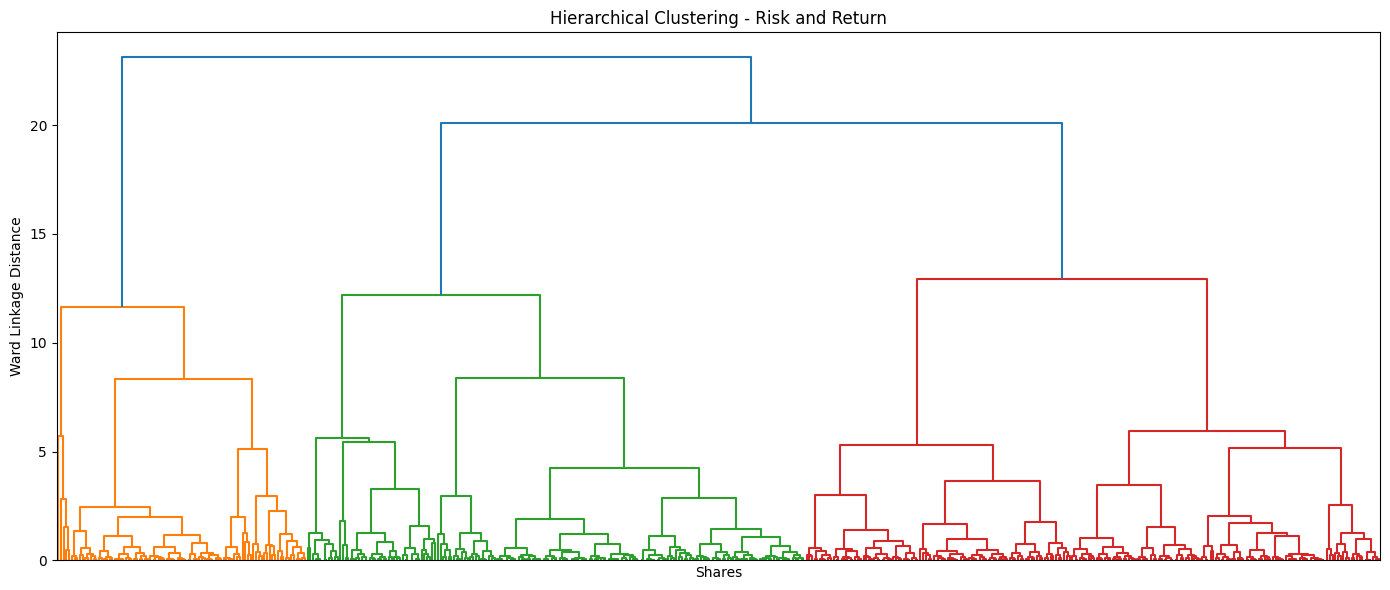

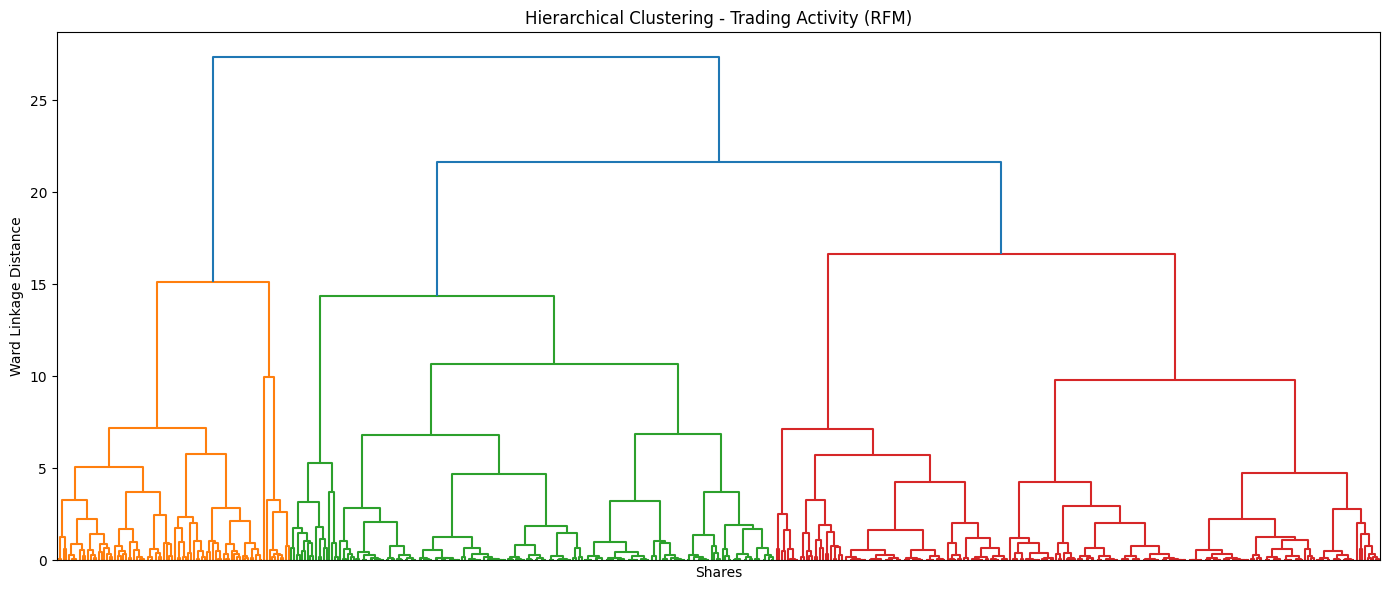

In [ ]:
# Task 2.2
# Import required libraries
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

# Create hierarchical clustering model for Risk and Return
risk_linkage = linkage(
    risk_return_scaled,
    method='ward',
    metric='euclidean'
)

# Create hierarchical clustering model for Trading Activity
rfm_linkage = linkage(
    trading_activity_scaled,
    method='ward',
    metric='euclidean'
)

# Plot Risk and Return dendrogram
plt.figure(figsize=(14, 6))
dendrogram(risk_linkage, no_labels=True)
plt.title('Hierarchical Clustering - Risk and Return')
plt.xlabel('Shares')
plt.ylabel('Ward Linkage Distance')
plt.tight_layout()
plt.show()

# Plot Trading Activity dendrogram
plt.figure(figsize=(14, 6))
dendrogram(rfm_linkage, no_labels=True)
plt.title('Hierarchical Clustering - Trading Activity (RFM)')
plt.xlabel('Shares')
plt.ylabel('Ward Linkage Distance')
plt.tight_layout()
plt.show()

In [ ]:
# Import required libraries
import pandas as pd
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Function to evaluate hierarchical clustering
def evaluate_hierarchical(data, linkage_matrix, matrix_name):

    results = []

    # Test cluster counts from 2 to 8
    for k in range(2, 9):

        # Build Agglomerative Clustering model
        model = AgglomerativeClustering(
            n_clusters=k,
            linkage='ward',
            metric='euclidean'
        )

        # Assign cluster labels
        labels = model.fit_predict(data)

        # Calculate silhouette score
        silhouette = silhouette_score(data, labels)

        # Calculate cluster sizes
        sizes = pd.Series(labels).value_counts().sort_index()

        # Store results
        results.append({
            'Clusters': k,
            'Silhouette Score': silhouette,
            'Cluster Sizes': sizes.to_dict()
        })

    results_df = pd.DataFrame(results)

    print(f"\n{matrix_name} Clustering Evaluation:")
    display(results_df)

    return results_df


# Evaluate Risk and Return clustering
risk_results = evaluate_hierarchical(
    risk_return_scaled,
    risk_linkage,
    "Risk and Return"
)

# Evaluate Trading Activity clustering
rfm_results = evaluate_hierarchical(
    trading_activity_scaled,
    rfm_linkage,
    "Trading Activity (RFM)"
)


Risk and Return Clustering Evaluation:


,Clusters,Silhouette Score,Cluster Sizes
0,2,0.339888,"{0: 396, 1: 92}"
1,3,0.292905,"{0: 212, 1: 92, 2: 184}"
2,4,0.265427,"{0: 184, 1: 92, 2: 114, 3: 98}"
3,5,0.287282,"{0: 92, 1: 136, 2: 114, 3: 98, 4: 48}"
4,6,0.304064,"{0: 136, 1: 87, 2: 114, 3: 98, 4: 48, 5: 5}"
5,7,0.306064,"{0: 87, 1: 48, 2: 114, 3: 98, 4: 114, 5: 5, 6:..."
6,8,0.313846,"{0: 114, 1: 48, 2: 5, 3: 98, 4: 114, 5: 31, 6:..."



Trading Activity (RFM) Clustering Evaluation:


,Clusters,Silhouette Score,Cluster Sizes
0,2,0.369340,"{0: 402, 1: 86}"
1,3,0.261434,"{0: 223, 1: 86, 2: 179}"
2,4,0.251355,"{0: 86, 1: 137, 2: 179, 3: 86}"
3,5,0.270088,"{0: 179, 1: 137, 2: 10, 3: 86, 4: 76}"
4,6,0.291391,"{0: 161, 1: 137, 2: 10, 3: 86, 4: 76, 5: 18}"
5,7,0.280443,"{0: 10, 1: 137, 2: 71, 3: 86, 4: 76, 5: 18, 6:..."
6,8,0.281642,"{0: 137, 1: 76, 2: 71, 3: 86, 4: 9, 5: 18, 6: ..."


In [ ]:
# Import Agglomerative Clustering
from sklearn.cluster import AgglomerativeClustering

# Evaluate cluster sizes and profiles for selected k values
for k in [2, 3, 4]:

    print(f"\n{'='*50}")
    print(f"RISK AND RETURN - k = {k}")
    print(f"{'='*50}")

    # Fit Risk and Return model
    risk_model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward',
        metric='euclidean'
    )

    risk_labels = risk_model.fit_predict(risk_return_scaled)

    # Display cluster sizes
    print("\nCluster sizes:")
    print(pd.Series(risk_labels).value_counts().sort_index())

    # Display profiles in original units
    risk_profile = risk_return_features.copy()
    risk_profile['Cluster'] = risk_labels

    print("\nCluster profiles:")
    display(risk_profile.groupby('Cluster').mean().round(4))

    print(f"\n{'='*50}")
    print(f"TRADING ACTIVITY - k = {k}")
    print(f"{'='*50}")

    # Fit Trading Activity model
    rfm_model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward',
        metric='euclidean'
    )

    rfm_labels = rfm_model.fit_predict(trading_activity_scaled)

    # Display cluster sizes
    print("\nCluster sizes:")
    print(pd.Series(rfm_labels).value_counts().sort_index())

    # Display profiles in original units
    rfm_profile = trading_activity_features.copy()
    rfm_profile['Cluster'] = rfm_labels

    print("\nCluster profiles:")
    display(rfm_profile.groupby('Cluster').mean().round(2))


RISK AND RETURN - k = 2

Cluster sizes:
0    396
1     92
Name: count, dtype: int64

Cluster profiles:


,Mean Weekly Return,Weekly Beta
Cluster,,
0,0.0021,0.8985
1,0.0063,1.2981



TRADING ACTIVITY - k = 2

Cluster sizes:
0    402
1     86
Name: count, dtype: int64

Cluster profiles:


,Recency,Frequency,Monetary
Cluster,,,
0,12.56,3.20,3.738926e+10
1,57.00,1.98,4.824805e+10



RISK AND RETURN - k = 3

Cluster sizes:
0    212
1     92
2    184
Name: count, dtype: int64

Cluster profiles:


,Mean Weekly Return,Weekly Beta
Cluster,,
0,0.0025,0.6371
1,0.0063,1.2981
2,0.0015,1.1998


... (2 outputs left out)


RISK AND RETURN - k = 4

Cluster sizes:
0    184
1     92
2    114
3     98
Name: count, dtype: int64

Cluster profiles:


,Mean Weekly Return,Weekly Beta
Cluster,,
0,0.0015,1.1998
1,0.0063,1.2981
2,0.0010,0.5741
3,0.0042,0.7104



TRADING ACTIVITY - k = 4

Cluster sizes:
0     86
1    137
2    179
3     86
Name: count, dtype: int64

Cluster profiles:


,Recency,Frequency,Monetary
Cluster,,,
0,57.00,1.98,4.824805e+10
1,11.28,2.64,9.051506e+09
2,12.15,2.94,7.024891e+10
3,15.44,4.66,1.413803e+10


In [ ]:
# Create final Ward hierarchical clustering models
# using four clusters for both feature matrices

# Risk and Return clustering
risk_final_model = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward',
    metric='euclidean'
)

risk_final_labels = risk_final_model.fit_predict(
    risk_return_scaled
)

# Trading Activity (RFM) clustering
rfm_final_model = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward',
    metric='euclidean'
)

rfm_final_labels = rfm_final_model.fit_predict(
    trading_activity_scaled
)

# Store cluster assignments
risk_cluster_results = risk_return_features.copy()
risk_cluster_results['Cluster'] = risk_final_labels

rfm_cluster_results = trading_activity_features.copy()
rfm_cluster_results['Cluster'] = rfm_final_labels

# Display final cluster sizes
print("Risk and Return - Final Cluster Sizes:")
display(risk_cluster_results['Cluster'].value_counts().sort_index())

print("Trading Activity - Final Cluster Sizes:")
display(rfm_cluster_results['Cluster'].value_counts().sort_index())

# Display final cluster profiles in original units
print("Risk and Return - Final Cluster Profiles:")
display(risk_cluster_results.groupby('Cluster').mean().round(4))

print("Trading Activity - Final Cluster Profiles:")
display(rfm_cluster_results.groupby('Cluster').mean().round(2))

# Calculate final silhouette scores
print("Risk and Return Silhouette:",
      silhouette_score(risk_return_scaled, risk_final_labels))

print("Trading Activity Silhouette:",
      silhouette_score(trading_activity_scaled, rfm_final_labels))

Risk and Return - Final Cluster Sizes:


,count
Cluster,
0,184
1,92
2,114
3,98


Trading Activity - Final Cluster Sizes:


,count
Cluster,
0,86
1,137
2,179
3,86


Risk and Return - Final Cluster Profiles:


,Mean Weekly Return,Weekly Beta
Cluster,,
0,0.0015,1.1998
1,0.0063,1.2981
2,0.0010,0.5741
3,0.0042,0.7104


Trading Activity - Final Cluster Profiles:


,Recency,Frequency,Monetary
Cluster,,,
0,57.00,1.98,4.824805e+10
1,11.28,2.64,9.051506e+09
2,12.15,2.94,7.024891e+10
3,15.44,4.66,1.413803e+10


Risk and Return Silhouette: 0.2654272573443968
Trading Activity Silhouette: 0.2513545540623517


In [ ]:

# Task 2.3

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# Set the cluster numbers to evaluate
k_values = range(2, 9)

# Store evaluation results
risk_kmeans_results = []
rfm_kmeans_results = []

# Evaluate Risk and Return feature matrix
for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(risk_return_scaled)

    risk_kmeans_results.append({
        'K': k,
        'Silhouette Score': silhouette_score(
            risk_return_scaled, labels
        ),
        'Inertia': model.inertia_,
        'Cluster Sizes': dict(
            pd.Series(labels).value_counts().sort_index()
        )
    })

# Evaluate Trading Activity feature matrix
for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(trading_activity_scaled)

    rfm_kmeans_results.append({
        'K': k,
        'Silhouette Score': silhouette_score(
            trading_activity_scaled, labels
        ),
        'Inertia': model.inertia_,
        'Cluster Sizes': dict(
            pd.Series(labels).value_counts().sort_index()
        )
    })

# Display results
risk_kmeans_table = pd.DataFrame(risk_kmeans_results)
rfm_kmeans_table = pd.DataFrame(rfm_kmeans_results)

print("RISK AND RETURN - K-MEANS EVALUATION")
display(risk_kmeans_table.round(4))

print("TRADING ACTIVITY - K-MEANS EVALUATION")
display(rfm_kmeans_table.round(4))


RISK AND RETURN - K-MEANS EVALUATION


,K,Silhouette Score,Inertia,Cluster Sizes
0,2,0.3868,625.0104,"{0: 345, 1: 143}"
1,3,0.3278,464.0772,"{0: 203, 1: 119, 2: 166}"
2,4,0.3254,373.9594,"{0: 134, 1: 166, 2: 147, 3: 41}"
3,5,0.3385,311.6512,"{0: 129, 1: 28, 2: 54, 3: 109, 4: 168}"
4,6,0.3294,266.9665,"{0: 140, 1: 119, 2: 16, 3: 56, 4: 79, 5: 78}"
5,7,0.3297,228.4597,"{0: 104, 1: 129, 2: 79, 3: 84, 4: 5, 5: 41, 6:..."
6,8,0.3575,196.4134,"{0: 139, 1: 77, 2: 40, 3: 74, 4: 4, 5: 47, 6: ..."


TRADING ACTIVITY - K-MEANS EVALUATION


,K,Silhouette Score,Inertia,Cluster Sizes
0,2,0.4238,1071.5853,"{0: 68, 1: 420}"
1,3,0.3251,800.7464,"{0: 151, 1: 274, 2: 63}"
2,4,0.3414,612.4751,"{0: 214, 1: 91, 2: 122, 3: 61}"
3,5,0.3580,517.0748,"{0: 200, 1: 68, 2: 11, 3: 122, 4: 87}"
4,6,0.3429,439.8740,"{0: 43, 1: 105, 2: 11, 3: 119, 4: 68, 5: 142}"
5,7,0.3460,390.2545,"{0: 106, 1: 65, 2: 15, 3: 141, 4: 119, 5: 41, ..."
6,8,0.3494,344.1558,"{0: 141, 1: 83, 2: 67, 3: 106, 4: 1, 5: 11, 6:..."


In [ ]:

# Create final K-means models using k=2

risk_kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

rfm_kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

# Generate cluster labels
risk_kmeans_labels = risk_kmeans_final.fit_predict(risk_return_scaled)
rfm_kmeans_labels = rfm_kmeans_final.fit_predict(trading_activity_scaled)

# Store original feature values with cluster labels
risk_kmeans_clusters = risk_return_features.copy()
risk_kmeans_clusters['Cluster'] = risk_kmeans_labels

rfm_kmeans_clusters = trading_activity_features.copy()
rfm_kmeans_clusters['Cluster'] = rfm_kmeans_labels

# Display cluster sizes
print("Risk and Return - K-means Cluster Sizes:")
print(risk_kmeans_clusters['Cluster'].value_counts().sort_index())

print("\nTrading Activity - K-means Cluster Sizes:")
print(rfm_kmeans_clusters['Cluster'].value_counts().sort_index())

# Display cluster profiles in original units
print("\nRisk and Return - K-means Cluster Profiles:")
print(risk_kmeans_clusters.groupby('Cluster').mean().round(4))

print("\nTrading Activity - K-means Cluster Profiles:")
print(rfm_kmeans_clusters.groupby('Cluster').mean().round(2))

# Display silhouette scores
print("\nRisk and Return Silhouette Score:",
      round(silhouette_score(risk_return_scaled, risk_kmeans_labels), 4))

print("Trading Activity Silhouette Score:",
      round(silhouette_score(trading_activity_scaled, rfm_kmeans_labels), 4))


Risk and Return - K-means Cluster Sizes:
Cluster
0    345
1    143
Name: count, dtype: int64

Trading Activity - K-means Cluster Sizes:
Cluster
0     68
1    420
Name: count, dtype: int64

Risk and Return - K-means Cluster Profiles:
         Mean Weekly Return  Weekly Beta
Cluster                                 
0                    0.0018       0.8178
1                    0.0053       1.3505

Trading Activity - K-means Cluster Profiles:
         Recency  Frequency      Monetary
Cluster                                  
0          63.34       1.78  8.067057e+10
1          13.44       3.18  3.260527e+10

Risk and Return Silhouette Score: 0.3868
Trading Activity Silhouette Score: 0.4238


In [ ]:

# Task 2.4
# Agglomerative Clustering - Risk and Return
print("AGGLOMERATIVE - RISK AND RETURN")
print(risk_cluster_results.groupby('Cluster').mean().round(4))

# K-means - Risk and Return
print("\nK-MEANS - RISK AND RETURN")
print(risk_kmeans_clusters.groupby('Cluster').mean().round(4))

# Agglomerative Clustering - Trading Activity
print("\nAGGLOMERATIVE - TRADING ACTIVITY")
print(rfm_cluster_results.groupby('Cluster').mean().round(2))

# K-means - Trading Activity
print("\nK-MEANS - TRADING ACTIVITY")
print(rfm_kmeans_clusters.groupby('Cluster').mean().round(2))


AGGLOMERATIVE - RISK AND RETURN
         Mean Weekly Return  Weekly Beta
Cluster                                 
0                    0.0015       1.1998
1                    0.0063       1.2981
2                    0.0010       0.5741
3                    0.0042       0.7104

K-MEANS - RISK AND RETURN
         Mean Weekly Return  Weekly Beta
Cluster                                 
0                    0.0018       0.8178
1                    0.0053       1.3505

AGGLOMERATIVE - TRADING ACTIVITY
         Recency  Frequency      Monetary
Cluster                                  
0          57.00       1.98  4.824805e+10
1          11.28       2.64  9.051506e+09
2          12.15       2.94  7.024891e+10
3          15.44       4.66  1.413803e+10

K-MEANS - TRADING ACTIVITY
         Recency  Frequency      Monetary
Cluster                                  
0          63.34       1.78  8.067057e+10
1          13.44       3.18  3.260527e+10


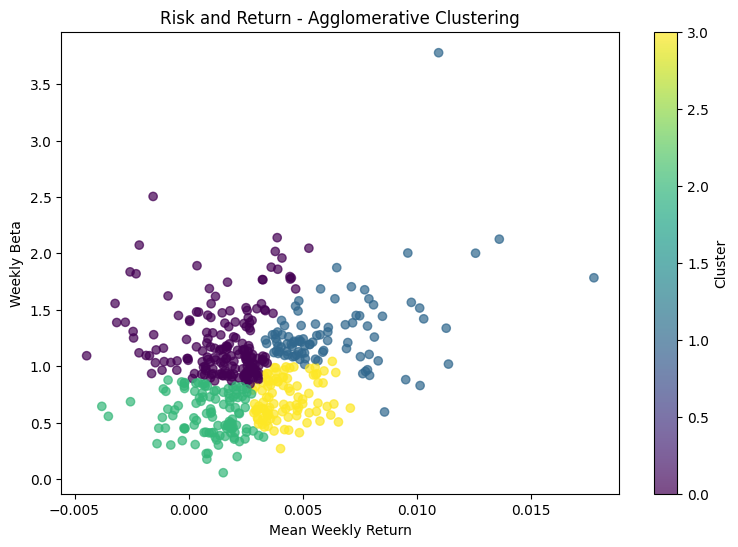

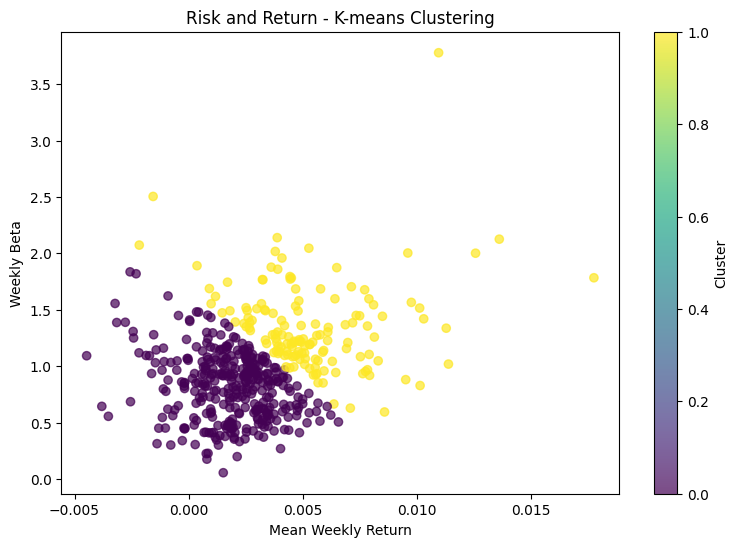

In [ ]:

import matplotlib.pyplot as plt

# Agglomerative Clustering
plt.figure(figsize=(9, 6))
plt.scatter(
    risk_cluster_results['Mean Weekly Return'],
    risk_cluster_results['Weekly Beta'],
    c=risk_cluster_results['Cluster'],
    cmap='viridis',
    alpha=0.7
)
plt.title('Risk and Return - Agglomerative Clustering')
plt.xlabel('Mean Weekly Return')
plt.ylabel('Weekly Beta')
plt.colorbar(label='Cluster')
plt.show()

# K-means Clustering
plt.figure(figsize=(9, 6))
plt.scatter(
    risk_kmeans_clusters['Mean Weekly Return'],
    risk_kmeans_clusters['Weekly Beta'],
    c=risk_kmeans_clusters['Cluster'],
    cmap='viridis',
    alpha=0.7
)
plt.title('Risk and Return - K-means Clustering')
plt.xlabel('Mean Weekly Return')
plt.ylabel('Weekly Beta')
plt.colorbar(label='Cluster')
plt.show()


Explained Variance Ratio:
[0.4579 0.3365]

Total Variance Explained:
0.7944


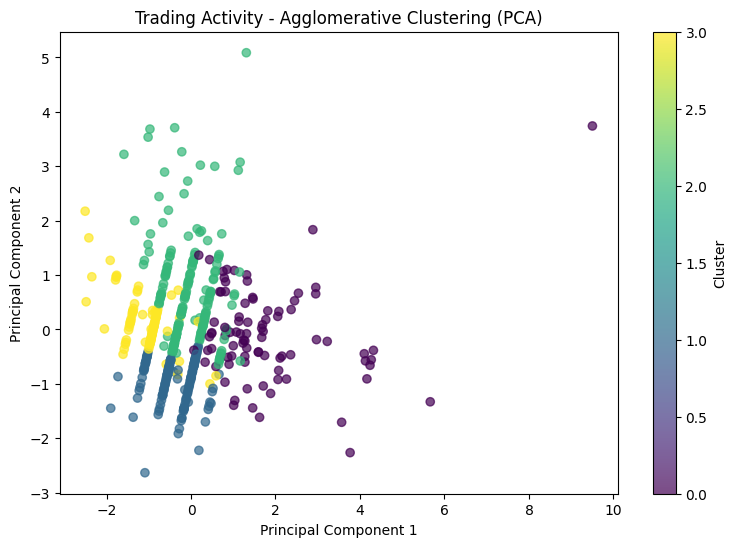

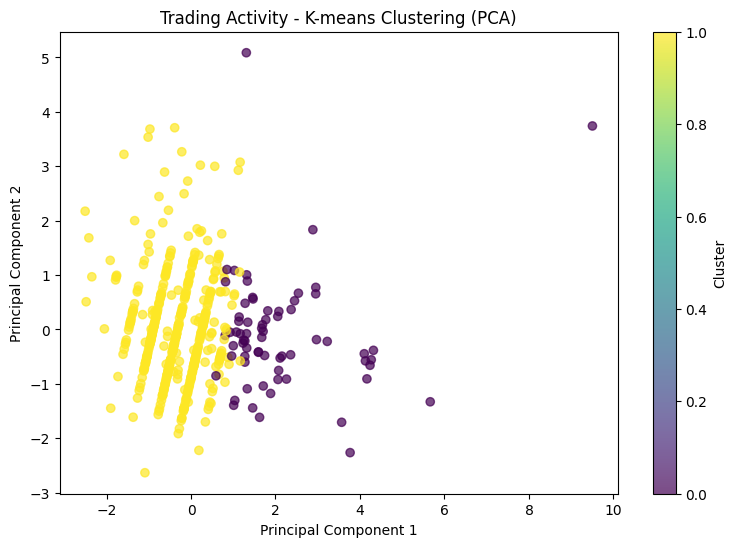

In [ ]:

from sklearn.decomposition import PCA
import pandas as pd
import matplotlib.pyplot as plt

# Reduce the three standardised RFM features into two dimensions
pca = PCA(n_components=2)

rfm_pca = pca.fit_transform(trading_activity_scaled)

# Store the PCA results
pca_df = pd.DataFrame(
    rfm_pca,
    columns=['Principal Component 1', 'Principal Component 2'],
    index=trading_activity_scaled.index
)

# Display explained variance
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_.round(4))

print("\nTotal Variance Explained:")
print(round(pca.explained_variance_ratio_.sum(), 4))

# Add cluster labels
pca_df['Agglomerative Cluster'] = rfm_cluster_results['Cluster']
pca_df['K-means Cluster'] = rfm_kmeans_clusters['Cluster']

# Agglomerative visualisation
plt.figure(figsize=(9, 6))
plt.scatter(
    pca_df['Principal Component 1'],
    pca_df['Principal Component 2'],
    c=pca_df['Agglomerative Cluster'],
    cmap='viridis',
    alpha=0.7
)
plt.title('Trading Activity - Agglomerative Clustering (PCA)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Cluster')
plt.show()

# K-means visualisation
plt.figure(figsize=(9, 6))
plt.scatter(
    pca_df['Principal Component 1'],
    pca_df['Principal Component 2'],
    c=pca_df['K-means Cluster'],
    cmap='viridis',
    alpha=0.7
)
plt.title('Trading Activity - K-means Clustering (PCA)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Cluster')
plt.show()


In [ ]:
print(pca.explained_variance_ratio_.round(4))
print(pca.explained_variance_ratio_.sum().round(4))

[0.4579 0.3365]
0.7944


In [ ]:
#Task 2.4 - Algorithm comparison using ARI
from sklearn.metrics import adjusted_rand_score

# Compare Agglomerative and K-means for Risk and Return
risk_ari = adjusted_rand_score(
    risk_cluster_results['Cluster'],
    risk_kmeans_clusters['Cluster']
)

# Compare Agglomerative and K-means for Trading Activity
rfm_ari = adjusted_rand_score(
    rfm_cluster_results['Cluster'],
    rfm_kmeans_clusters['Cluster']
)

# Display comparison results
print("Risk and Return - Adjusted Rand Index:", round(risk_ari, 4))
print("Trading Activity - Adjusted Rand Index:", round(rfm_ari, 4))


Risk and Return - Adjusted Rand Index: 0.2125
Trading Activity - Adjusted Rand Index: 0.1702


RFM Correlation Matrix:
           Recency  Frequency  Monetary
Recency     1.0000    -0.3461    0.1528
Frequency  -0.3461     1.0000    0.0128
Monetary    0.1528     0.0128    1.0000


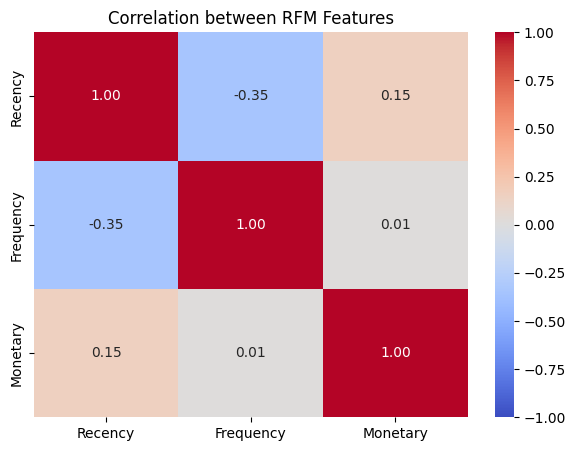

In [ ]:

# 2.5 RFM sensitivity and correlated inputs
# 2.5.1 Correlation analysis

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Copy the original RFM features
rfm_correlation = trading_activity_features.copy()

# Apply log1p transformation to Monetary
rfm_correlation['Monetary'] = np.log1p(
    rfm_correlation['Monetary']
)

# Calculate correlations between R, F and log1p(M)
correlation_matrix = rfm_correlation.corr()

# Display the correlation matrix
print("RFM Correlation Matrix:")
print(correlation_matrix.round(4))

# Create a correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation between RFM Features')
plt.show()


In [ ]:
# 2.5.2 Removal of Monetary
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
import pandas as pd

# Create a reduced RFM matrix using Recency and Frequency only
rf_only_features = trading_activity_features[['Recency', 'Frequency']].copy()

# Standardise the reduced features again
rf_scaler = StandardScaler()

rf_only_scaled = pd.DataFrame(
    rf_scaler.fit_transform(rf_only_features),
    columns=rf_only_features.columns,
    index=rf_only_features.index
)

# Apply Ward hierarchical clustering using the same k=4
rf_only_model = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward',
    metric='euclidean'
)

# Generate new cluster labels
rf_only_labels = rf_only_model.fit_predict(rf_only_scaled)

# Store the reduced clustering results
rf_only_results = rf_only_features.copy()
rf_only_results['Cluster'] = rf_only_labels

# Display cluster sizes
print("R and F Only - Cluster Sizes:")
print(rf_only_results['Cluster'].value_counts().sort_index())

# Display cluster profiles
print("\nR and F Only - Cluster Profiles:")
print(rf_only_results.groupby('Cluster').mean().round(2))


R and F Only - Cluster Sizes:
Cluster
0    273
1     80
2    125
3     10
Name: count, dtype: int64

R and F Only - Cluster Profiles:
         Recency  Frequency
Cluster                    
0          12.88       3.85
1          48.59       2.26
2          11.04       1.80
3         116.80       0.00


In [ ]:

from sklearn.metrics import adjusted_rand_score

# Align both clustering solutions using the same shares
common_shares = rfm_cluster_results.index.intersection(
    rf_only_results.index
)

original_labels = rfm_cluster_results.loc[common_shares, 'Cluster']
reduced_labels = rf_only_results.loc[common_shares, 'Cluster']

# Calculate Adjusted Rand Index
ari_score = adjusted_rand_score(original_labels, reduced_labels)

print("Original RFM vs R and F Only - ARI:", round(ari_score, 4))

# Compare Monetary values in the original RFM clusters
print("\nOriginal RFM - Average Monetary by Cluster:")
print(
    rfm_cluster_results.groupby('Cluster')['Monetary']
    .mean().round(2)
)

# Compare Monetary values after removing Monetary from clustering
print("\nR and F Only - Average Monetary by Cluster:")
print(
    trading_activity_features.loc[common_shares]
    .assign(Cluster=reduced_labels)
    .groupby('Cluster')['Monetary']
    .mean().round(2)
)


Original RFM vs R and F Only - ARI: 0.2278

Original RFM - Average Monetary by Cluster:
Cluster
0    4.824805e+10
1    9.051506e+09
2    7.024891e+10
3    1.413803e+10
Name: Monetary, dtype: float64

R and F Only - Average Monetary by Cluster:
Cluster
0    3.929740e+10
1    2.702459e+10
2    3.433790e+10
3    1.997420e+11
Name: Monetary, dtype: float64


In [ ]:

# Task 3.2.1
# Check whether your S&P 500 sector information is available
print([name for name in globals()
       if 'sp500' in name.lower() or 'sector' in name.lower()])


['sp500_sector_data', 'sector_data', 'risk_sector', 'rfm_sector']


In [ ]:
import os

print(os.listdir())


['.config', 'sp500_stock_data (1).pkl', 'sample_data']


In [ ]:
import pandas as pd
import requests
from io import StringIO

url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)
response.raise_for_status()

sp500_sector_data = pd.read_html(StringIO(response.text))[0]

sp500_sector_data = sp500_sector_data[
    ["Symbol", "Security", "GICS Sector"]
]

print(sp500_sector_data.head())
print("Shape:", sp500_sector_data.shape)

  Symbol             Security             GICS Sector
0    MMM                   3M             Industrials
1    AOS          A. O. Smith             Industrials
2    ABT  Abbott Laboratories             Health Care
3   ABBV               AbbVie             Health Care
4    ACN            Accenture  Information Technology
Shape: (503, 3)


In [ ]:
# Match sector information with the 488 shares
sector_data = sp500_sector_data[
    sp500_sector_data["Symbol"].isin(common_tickers)
].copy()

sector_data = sector_data.set_index("Symbol")

# Check the matching results
print("Shares matched:", len(sector_data))
print("Missing sectors:", sector_data["GICS Sector"].isna().sum())

print("\nSector distribution:")
print(sector_data["GICS Sector"].value_counts())

Shares matched: 486
Missing sectors: 0

Sector distribution:
GICS Sector
Industrials               79
Information Technology    74
Financials                73
Health Care               58
Consumer Discretionary    47
Consumer Staples          31
Utilities                 30
Real Estate               30
Materials                 24
Communication Services    20
Energy                    20
Name: count, dtype: int64


In [ ]:
#Identify the two missing shares

unmatched_tickers = sorted(set(common_tickers) - set(sector_data.index))

print("Unmatched tickers:", unmatched_tickers)
print("Number of unmatched shares:", len(unmatched_tickers))

Unmatched tickers: ['BF-B', 'BRK-B']
Number of unmatched shares: 2


In [ ]:
# Correct the two unmatched tickers
# Add the two missing sector classifications
sector_data.loc["BF-B"] = [
    "Brown-Forman",
    "Consumer Staples"
]

sector_data.loc["BRK-B"] = [
    "Berkshire Hathaway",
    "Financials"
]

# Check the final matching
print("Total matched shares:", len(sector_data))
print("\nSector distribution:")
print(sector_data["GICS Sector"].value_counts())

Total matched shares: 488

Sector distribution:
GICS Sector
Industrials               79
Information Technology    74
Financials                74
Health Care               58
Consumer Discretionary    47
Consumer Staples          32
Utilities                 30
Real Estate               30
Materials                 24
Communication Services    20
Energy                    20
Name: count, dtype: int64


In [ ]:
# Combine Agglomerative cluster labels with sector information
risk_sector = risk_cluster_results[["Cluster"]].join(
    sector_data[["GICS Sector"]], how="inner"
)

rfm_sector = rfm_cluster_results[["Cluster"]].join(
    sector_data[["GICS Sector"]], how="inner"
)

# Sector counts in each Risk and Return cluster
print("RISK AND RETURN - SECTOR COUNTS")
print(pd.crosstab(risk_sector["Cluster"], risk_sector["GICS Sector"]))

# Sector percentages in each Risk and Return cluster
print("\nRISK AND RETURN - SECTOR PERCENTAGES")
print(pd.crosstab(
    risk_sector["Cluster"],
    risk_sector["GICS Sector"],
    normalize="index"
).mul(100).round(1))

# Sector counts in each Trading Activity cluster
print("\nTRADING ACTIVITY - SECTOR COUNTS")
print(pd.crosstab(rfm_sector["Cluster"], rfm_sector["GICS Sector"]))

# Sector percentages in each Trading Activity cluster
print("\nTRADING ACTIVITY - SECTOR PERCENTAGES")
print(pd.crosstab(
    rfm_sector["Cluster"],
    rfm_sector["GICS Sector"],
    normalize="index"
).mul(100).round(1))

RISK AND RETURN - SECTOR COUNTS
GICS Sector  Communication Services  Consumer Discretionary  Consumer Staples  \
Cluster                                                                         
0                                 5                      23                 3   
1                                 5                      11                 0   
2                                 5                       4                24   
3                                 5                       9                 5   

GICS Sector  Energy  Financials  Health Care  Industrials  \
Cluster                                                     
0                 0          30           24           33   
1                 4          13            2           21   
2                 0           3           24           14   
3                16          28            8           11   

GICS Sector  Information Technology  Materials  Real Estate  Utilities  
Cluster                                  

In [ ]:
ghdjdkendemfnej